# ACME Inc. — Employee Performance & Talent Insights

This notebook answers ACME's seven business questions using the **Gold layer** of the
data lake (`s3://<bucket>/gold/`). It is written for two audiences:

* **Business readers** — each section starts with the question and ends with a plain-English answer.
* **Technical readers** — each section shows which Gold table it uses and the exact logic.

**Pipeline:** PostgreSQL + S3 landing files → **Bronze** (raw, immutable) → **Silver** (validated with
Pydantic, cleaned with PySpark) → **Gold** (one dataset per business question) → this notebook.

> Run the pipeline first (`./data/acme-performance/run_local.sh`), then *Run All*.
> The notebook reads the same environment settings as the job (`data/acme-performance/.env.local`
> locally; injected variables in the cloud).

In [1]:
import io
import json
import os
from pathlib import Path

import boto3
import matplotlib.pyplot as plt
import pandas as pd
from botocore.config import Config

# --- Settings: same variables as the pipeline job (nothing hard-coded) ---------------
env_file = next((p for p in [Path("data/acme-performance/.env.local"),
                             Path("../data/acme-performance/.env.local")] if p.exists()), None)
if env_file:  # local run: load .env.local without overriding variables already set
    for line in env_file.read_text().splitlines():
        if line.strip() and not line.lstrip().startswith("#") and "=" in line:
            key, value = line.split("=", 1)
            os.environ.setdefault(key.strip(), value.strip())
if os.getenv("IS_LOCAL", "true") == "true":  # LocalStack accepts any credentials
    os.environ.setdefault("AWS_ACCESS_KEY_ID", "test")
    os.environ.setdefault("AWS_SECRET_ACCESS_KEY", "test")

BUCKET = os.environ["DATA_LAKE_BUCKET"]
ENDPOINT = os.getenv("AWS_ENDPOINT_URL") or None
s3 = boto3.client("s3", region_name=os.getenv("AWS_REGION", "ap-south-1"), endpoint_url=ENDPOINT,
                  config=Config(s3={"addressing_style": "path"} if ENDPOINT else {}))


def read_gold(table: str) -> pd.DataFrame:
    """Read every Parquet file of one Gold table into pandas."""
    keys = [o["Key"] for page in s3.get_paginator("list_objects_v2").paginate(Bucket=BUCKET, Prefix=f"gold/{table}/")
            for o in page.get("Contents", []) if o["Key"].endswith(".parquet")]
    if not keys:
        raise FileNotFoundError(f"gold/{table} is empty - run the pipeline first")
    return pd.concat([pd.read_parquet(io.BytesIO(s3.get_object(Bucket=BUCKET, Key=k)["Body"].read()))
                      for k in keys], ignore_index=True)


def latest_manifest(layer: str) -> dict:
    """Return the newest lineage manifest written by a pipeline stage."""
    keys = sorted(o["Key"] for page in s3.get_paginator("list_objects_v2").paginate(Bucket=BUCKET, Prefix=f"{layer}/_lineage/")
                  for o in page.get("Contents", []))
    succeeded = [json.loads(s3.get_object(Bucket=BUCKET, Key=k)["Body"].read()) for k in keys]
    succeeded = [m for m in succeeded if m.get("status") == "SUCCEEDED"]
    return succeeded[-1]


# --- Chart style: validated reference palette (light surface) ------------------------
BLUE, ORANGE = "#2a78d6", "#eb6834"                 # categorical slots 1-2
DIVERGING = {"neg": "#d03b3b", "mid": "#c3c2b7", "pos": "#2a78d6"}
STATUS = {"Low": "#0ca30c", "Medium": "#fab219", "High": "#d03b3b"}   # good / warning / critical
TEXT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": TEXT, "axes.titlecolor": TEXT, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "figure.dpi": 110, "font.size": 10,
})
pd.set_option("display.max_columns", 20)
print(f"Reading Gold data from s3://{BUCKET}/gold/ ({'LocalStack' if ENDPOINT else 'AWS'})")

Reading Gold data from s3://coding-workshop-datalake-1bd9f4ac/gold/ (LocalStack)


## 0. Data quality at a glance

Before trusting any answer, check what the pipeline loaded and what it **rejected**. Silver
writes a reconciliation per dataset: `rows read = duplicates removed + rows rejected + rows written`.
Rejected rows are kept (with a reason) in `silver/_quarantine/` — nothing is silently dropped.

In [2]:
silver = latest_manifest("silver")
quality = pd.DataFrame(silver["records"])[["entity", "rows_read", "duplicates_removed",
                                           "rows_rejected", "rows_written", "reconciled"]]
gold = latest_manifest("gold")
print(f"Silver run {silver['run_id']}  |  Gold run {gold['run_id']}")
quality

Silver run 20261014T180508Z-424f5b93  |  Gold run 20261014T181114Z-68bab83d


,entity,rows_read,duplicates_removed,rows_rejected,rows_written,reconciled
0,teams,100,0,0,100,True
1,competencies,40,0,0,40,True
2,employees,2000,0,0,2000,True
3,projects,33,0,0,33,True
4,performance_reviews,4000,0,0,4000,True
5,competency_assessments,4000,0,0,4000,True
6,talent_review,2000,0,0,2000,True
7,learning_activity,29868,152,142,29574,True


**Reading it:** all seven database tables passed every schema and foreign-key check. The learning-event
feed is where the problems were: duplicate deliveries, broken JSON lines, missing employee IDs and
unparseable dates. Those events are excluded from the analysis below and kept in quarantine for follow-up.

## 1. What are the performance ratings and review history for each employee?

**Gold table:** `employee_performance_history` — one row per employee per review period, with the change
from the previous review.

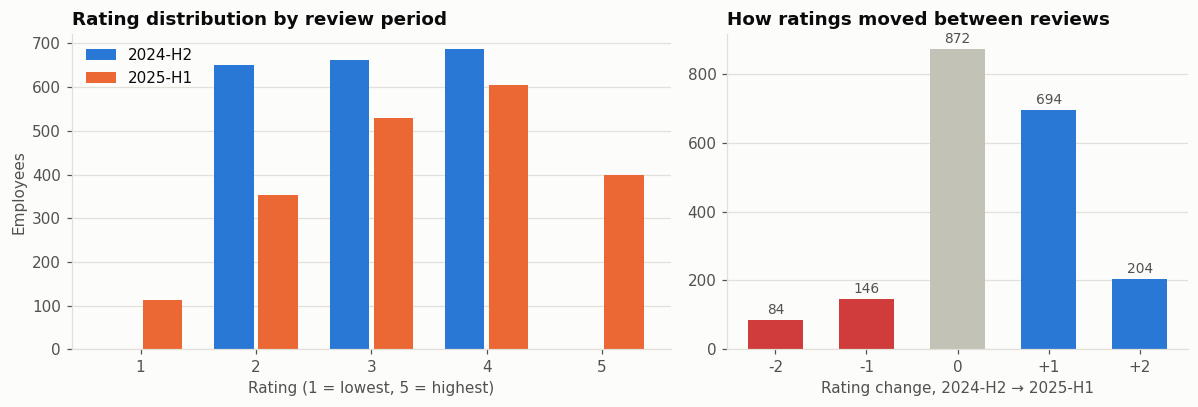

,count,mean,median
review_period,,,
2024-H2,2000,3.02,3.0
2025-H1,2000,3.41,4.0


In [3]:
history = read_gold("employee_performance_history")
dist = (history.pivot_table(index="rating", columns="review_period", values="employee_id", aggfunc="count")
        .reindex(range(1, 6)).fillna(0).astype(int))
periods = list(dist.columns)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
width = 0.38
for i, (period, color) in enumerate(zip(periods, [BLUE, ORANGE])):
    xs = [r + (i - 0.5) * width for r in dist.index]
    ax.bar(xs, dist[period], width=width - 0.04, color=color, label=period)
ax.set_xticks(list(dist.index), [f"{r}" for r in dist.index])
ax.set_xlabel("Rating (1 = lowest, 5 = highest)")
ax.set_ylabel("Employees")
ax.set_title("Rating distribution by review period")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)

change = history["rating_change"].dropna().astype(int).value_counts().sort_index()
ax = axes[1]
colors = [DIVERGING["neg"] if c < 0 else DIVERGING["pos"] if c > 0 else DIVERGING["mid"] for c in change.index]
bars = ax.bar([f"{c:+d}" if c else "0" for c in change.index], change.values, color=colors, width=0.6)
ax.bar_label(bars, padding=2, color=MUTED, fontsize=9)
ax.set_xlabel("Rating change, 2024-H2 → 2025-H1")
ax.set_title("How ratings moved between reviews")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

summary = history.groupby("review_period")["rating"].agg(["count", "mean", "median"]).round(2)
summary

In [4]:
# Review history for any employee (example: the first five employees)
history.sort_values(["employee_id", "review_period"])[
    ["employee_id", "employee_name", "team_name", "review_period", "rating", "previous_rating",
     "rating_change", "manager_comment"]].head(10)

,employee_id,employee_name,team_name,review_period,rating,previous_rating,rating_change,manager_comment
0,1,Heather Davis,Team LightYellow-1,2024-H2,3,NaN,NaN,Delivered on commitments with no major concerns.
1,1,Heather Davis,Team LightYellow-1,2025-H1,4,3.0,1.0,Delivered on commitments with no major concerns.
2,2,Kristie Heath,Team LightYellow-1,2024-H2,4,NaN,NaN,Delivered on commitments with no major concerns.
3,2,Kristie Heath,Team LightYellow-1,2025-H1,5,4.0,1.0,"Solid, consistent contributor this cycle."
4,3,Brandon Scott,Team LightYellow-1,2024-H2,4,NaN,NaN,"Solid, consistent contributor this cycle."
5,3,Brandon Scott,Team LightYellow-1,2025-H1,5,4.0,1.0,"Solid, consistent contributor this cycle."
6,4,Gregory Williams,Team LightYellow-1,2024-H2,4,NaN,NaN,Met expectations across all core responsibilit...
7,4,Gregory Williams,Team LightYellow-1,2025-H1,4,4.0,0.0,"Solid, consistent contributor this cycle."
8,5,Linda Murray,Team LightYellow-1,2024-H2,2,NaN,NaN,Met expectations across all core responsibilit...
9,5,Linda Murray,Team LightYellow-1,2025-H1,3,2.0,1.0,Strong upward trend across all review dimensions.


**Answer:** every employee has two reviews (2024-H2 and 2025-H1). Ratings shifted upwards between the two
periods: far more employees improved than declined. The table above shows the full history for each employee;
filter it by `employee_id` to see one person.

## 2. Which employees have critical skill gaps in key competencies?

**Gold tables:** `employee_skill_gaps` (one row per employee per competency) and `competency_coverage`
(one row per competency).
**Rule:** a gap is **critical** when the required level is **2 or more levels** above the employee's proficiency.

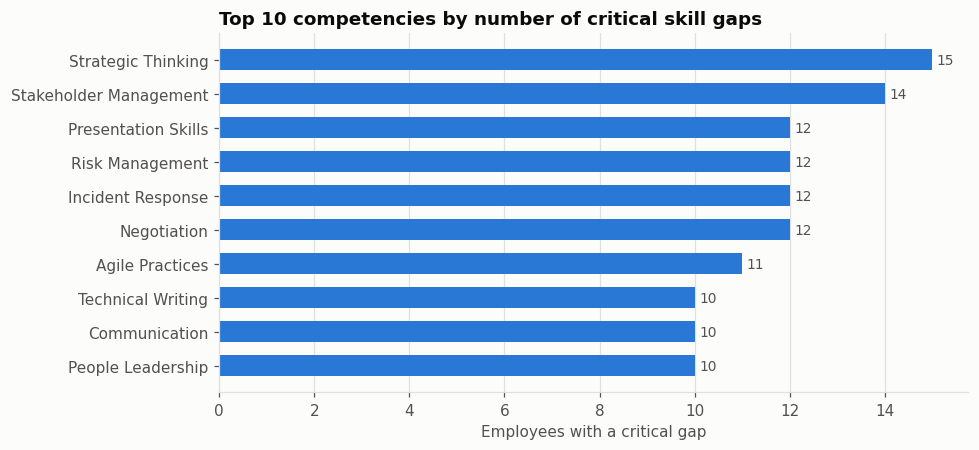

325 critical gaps across 317 employees (16% of assessed employees).


,employee_id,employee_name,department,competency_name,category,proficiency_level,required_level,gap_levels
38,159,Stacey Sanders,Engineering,Conflict Resolution,Leadership,2,4,2
41,174,Michelle Ferguson,Data & Analytics,Presentation Skills,Domain,1,3,2
48,201,Rebecca Johnson,Data & Analytics,SQL,Technical,2,4,2
49,203,Michael Smith,Data & Analytics,Public Speaking,Domain,2,4,2
62,259,Joshua Rojas,Marketing,Regulatory Compliance,Domain,1,3,2
69,291,Alejandro Wilson,Product,Performance Tuning,Technical,2,4,2
74,301,Danielle Myers,Product,Project Management,Domain,1,3,2
95,418,Lisa Hampton,Sales,Localization,Domain,1,3,2
96,421,Javier Stephenson,Sales,People Leadership,Leadership,1,3,2
97,425,Brian Singh,Sales,Onboarding & Enablement,Domain,2,4,2


In [5]:
gaps = read_gold("employee_skill_gaps")
coverage = read_gold("competency_coverage")
top = coverage.sort_values("critical_gap_count", ascending=True).tail(10)

fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.barh(top["competency_name"], top["critical_gap_count"], color=BLUE, height=0.6)
ax.bar_label(bars, padding=3, color=MUTED, fontsize=9)
ax.set_xlabel("Employees with a critical gap")
ax.set_title("Top 10 competencies by number of critical skill gaps")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

critical = gaps[gaps["is_critical_gap"]]
print(f"{len(critical)} critical gaps across {critical['employee_id'].nunique()} employees "
      f"({critical['employee_id'].nunique() / gaps['employee_id'].nunique():.0%} of assessed employees).")
critical.sort_values("gap_levels", ascending=False)[
    ["employee_id", "employee_name", "department", "competency_name", "category",
     "proficiency_level", "required_level", "gap_levels"]].head(10)

**Answer:** most assessments meet the required level, but a focused group of employees has critical gaps.
The competencies with the most critical gaps (top of the chart) are the best candidates for targeted training.
The table lists the employees with the largest gaps first.

## 3. Who are the high-potential employees ready for promotion?

**Gold table:** `promotion_readiness` — one row per employee.
**Promotion candidate =** potential **High** + readiness **Ready Now** + latest rating **≥ 4** + **no critical skill gaps**.

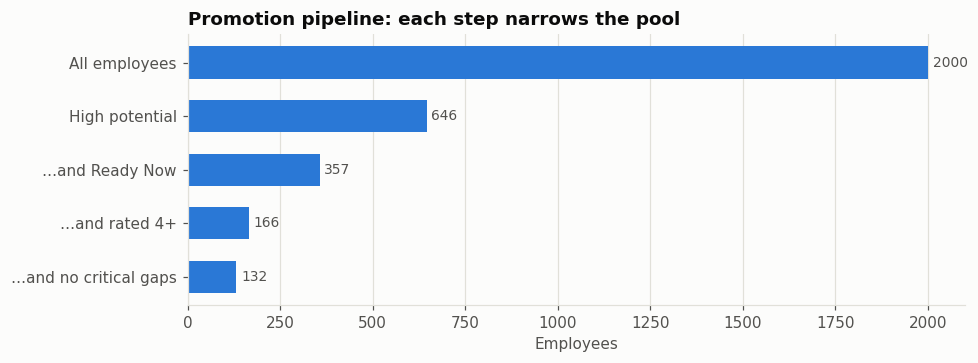

132 promotion candidates. By department:


department,Data & Analytics,Human Resources,Product,Customer Support,Engineering,Sales,Operations,Design,Marketing,Finance
candidates,19,19,18,14,14,13,12,9,7,7


,employee_id,employee_name,job_level,team_name,department,latest_rating,avg_rating,rating_trend
28,248,Lindsey Gonzales,Senior Manager,Team Moccasin-13,Customer Support,5,4.5,improving
44,359,Cameron Williams,Manager,Team YellowGreen-19,Data & Analytics,5,4.5,improving
86,701,Yolanda Foley,IC2,Team SlateBlue-36,Marketing,5,4.5,improving
124,1097,Dakota Mendez,Director,Team LightPink-56,Engineering,5,4.5,improving
275,268,Heather Bowman,IC2,Team Cornsilk-15,Engineering,5,4.5,improving
302,498,Christina Herrera,Senior IC,Team DarkGreen-26,Human Resources,5,4.5,improving
448,1612,Michael Stein,Director,Team Blue-83,Operations,5,4.5,improving
468,1750,Kevin Bryant,IC2,Team HoneyDew-91,Finance,5,4.5,improving
514,84,Daniel Osborne,Manager,Team SlateBlue-6,Customer Support,5,4.5,improving
574,559,David Young,Director,Team MediumBlue-30,Design,5,4.5,improving


In [6]:
promo = read_gold("promotion_readiness")
funnel = pd.Series({
    "All employees": len(promo),
    "High potential": int((promo["potential_rating"] == "High").sum()),
    "…and Ready Now": int(((promo["potential_rating"] == "High") & (promo["promotion_readiness"] == "Ready Now")).sum()),
    "…and rated 4+": int(((promo["potential_rating"] == "High") & (promo["promotion_readiness"] == "Ready Now")
                          & (promo["latest_rating"] >= 4)).sum()),
    "…and no critical gaps": int(promo["is_promotion_candidate"].sum()),
})

fig, ax = plt.subplots(figsize=(9, 3.4))
bars = ax.barh(funnel.index[::-1], funnel.values[::-1], color=BLUE, height=0.6)
ax.bar_label(bars, padding=3, color=MUTED, fontsize=9)
ax.set_xlabel("Employees")
ax.set_title("Promotion pipeline: each step narrows the pool")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

candidates = promo[promo["is_promotion_candidate"]].sort_values(["latest_rating", "avg_rating"], ascending=False)
print(f"{len(candidates)} promotion candidates. By department:")
display(candidates["department"].value_counts().rename("candidates").to_frame().T)
candidates[["employee_id", "employee_name", "job_level", "team_name", "department",
            "latest_rating", "avg_rating", "rating_trend"]].head(10)

**Answer:** of the high-potential employees, a subset are rated "Ready Now". Applying performance (latest rating ≥ 4)
and skills (no critical gaps) leaves the **promotion candidates** listed above — the strongest succession-planning
shortlist the data supports.

## 4. What training and development activities has each employee completed?

**Gold tables:** `employee_training_summary` (one row per employee, including employees with no activity) and
`employee_course_progress` (one row per employee per course).

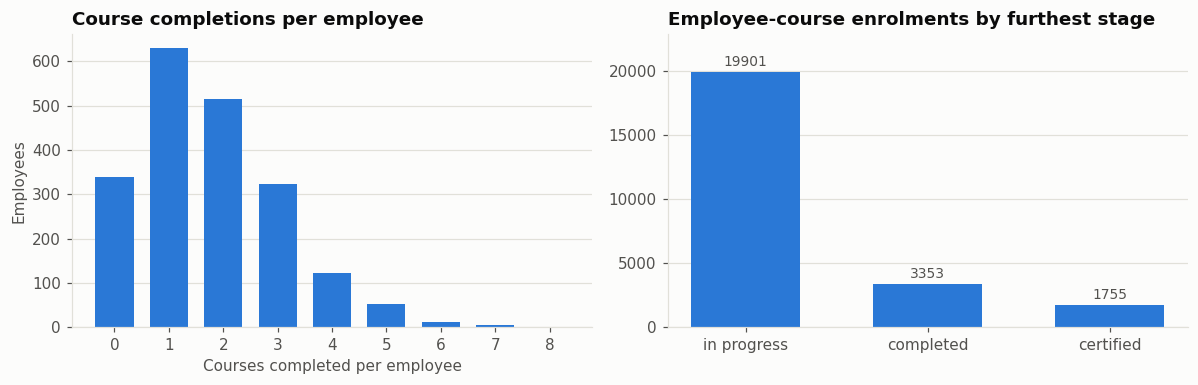

As of 2026-09-02: 3490 course completions, 1764 certifications; 14 employees had no learning activity in the last 12 months.


,employee_id,employee_name,department,enrollments,courses_completed,certifications_earned,avg_quiz_score,last_activity_date
1761,289,Mark Castillo,Product,4,8,0,31.5,2026-08-14
559,445,Kristen Johnson,Data & Analytics,3,7,0,69.0,2026-08-03
1576,595,Stephanie Barker,Human Resources,3,7,0,43.0,2026-07-09
1609,987,Bryan Ware,Sales,3,7,3,35.7,2026-08-27
246,75,Robert Hayes,Operations,3,7,0,78.5,2026-08-06
748,1912,Arthur Flores,Operations,2,6,0,83.0,2026-06-16
876,819,Alexis Taylor,Data & Analytics,1,6,3,70.8,2026-07-08
442,1553,Jordan Jefferson,Customer Support,3,6,0,74.6,2026-05-11
924,1198,Joseph Delgado,Sales,0,6,0,62.1,2026-07-01
355,826,Jane Dalton,Data & Analytics,4,6,1,44.0,2026-05-15


In [7]:
training = read_gold("employee_training_summary")
progress = read_gold("employee_course_progress")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
counts = training["courses_completed"].value_counts().sort_index()
axes[0].bar(counts.index.astype(str), counts.values, color=BLUE, width=0.7)
axes[0].set_xlabel("Courses completed per employee")
axes[0].set_ylabel("Employees")
axes[0].set_title("Course completions per employee")
axes[0].grid(axis="x", visible=False)

status = progress["status"].value_counts().reindex(["in progress", "completed", "certified"]).fillna(0)
bars = axes[1].bar(status.index, status.values, color=BLUE, width=0.6)
axes[1].bar_label(bars, padding=2, color=MUTED, fontsize=9)
axes[1].set_title("Employee-course enrolments by furthest stage")
axes[1].set_ylim(0, status.max() * 1.15)
axes[1].grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

print(f"As of {training['as_of_date'].iloc[0]}: {int(training['courses_completed'].sum())} course completions, "
      f"{int(training['certifications_earned'].sum())} certifications; "
      f"{int((~training['active_last_12_months']).sum())} employees had no learning activity in the last 12 months.")
training.sort_values("courses_completed", ascending=False)[
    ["employee_id", "employee_name", "department", "enrollments", "courses_completed",
     "certifications_earned", "avg_quiz_score", "last_activity_date"]].head(10)

**Answer:** the summary table gives every employee's training record (enrolments, completions, certifications,
quiz scores, last activity); `employee_course_progress` lists each course and how far the employee got.
Almost every employee has *some* recent learning activity (only a handful are inactive for 12 months), but many
enrolments are still in progress and a sizeable group has not completed any course yet — a follow-up opportunity.

## 5. Which employees are at risk of attrition based on performance trends?

**Gold table:** `attrition_risk` — one row per employee.

The data has **no record of who actually left**, so this is a transparent **rule-based risk score**, not a prediction:

| Signal | Points |
|---|---|
| Talent-review attrition label (Low / Medium / High) | 1 / 2 / 3 |
| Rating **declined** between the two reviews | +1 |
| Latest rating is **low** (≤ 2) | +1 |
| **No learning activity** in the last 12 months | +1 |

Risk band: **High** ≥ 4 points, **Medium** = 3, **Low** ≤ 2.

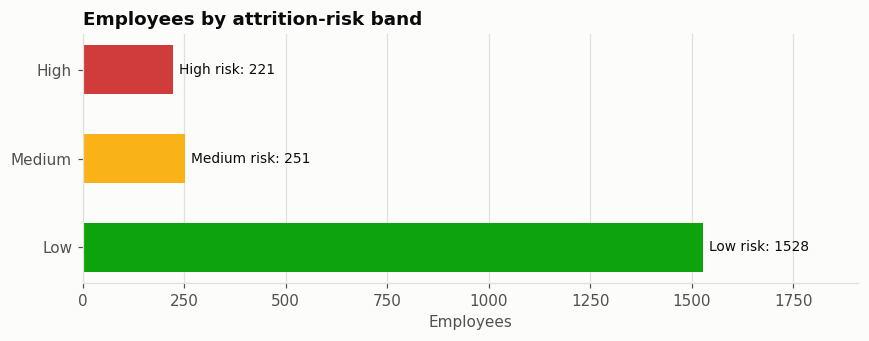

Talent-review label vs rating trend (employees):


rating_trend,declining,improving,stable
attrition_risk,,,
Low,18,534,525
Medium,70,280,262
High,142,84,85


,employee_id,employee_name,department,attrition_risk,previous_rating,latest_rating,rating_trend,active_last_12_months,risk_score,risk_band
48,49,Brandon Weiss,Sales,High,2,1,declining,True,5,High
63,64,Morgan Stewart,Operations,High,2,1,declining,True,5,High
110,111,Brian Brock,Finance,High,2,1,declining,True,5,High
122,123,Matthew Keller,Finance,High,2,1,declining,True,5,High
193,194,Carly Bennett,Data & Analytics,High,3,1,declining,True,5,High
228,229,Crystal Moore,Customer Support,High,3,1,declining,True,5,High
231,232,Joseph Ferrell,Customer Support,High,2,1,declining,True,5,High
245,246,Brian Jones,Customer Support,High,2,1,declining,True,5,High
256,257,Raymond Waters,Marketing,High,3,1,declining,True,5,High
294,295,Paula Davies,Product,High,3,1,declining,True,5,High


In [8]:
risk = read_gold("attrition_risk")
bands = risk["risk_band"].value_counts().reindex(["Low", "Medium", "High"]).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(8, 3.2))
bars = ax.barh(bands.index, bands.values, color=[STATUS[b] for b in bands.index], height=0.55)
ax.bar_label(bars, labels=[f"{b} risk: {v}" for b, v in bands.items()], padding=4, color=TEXT, fontsize=9)
ax.set_xlabel("Employees")
ax.set_title("Employees by attrition-risk band")
ax.set_xlim(0, bands.max() * 1.25)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

signals = pd.crosstab(risk["attrition_risk"], risk["rating_trend"]).reindex(["Low", "Medium", "High"])
print("Talent-review label vs rating trend (employees):")
display(signals)
risk.sort_values(["risk_score", "latest_rating"], ascending=[False, True])[
    ["employee_id", "employee_name", "department", "attrition_risk", "previous_rating", "latest_rating",
     "rating_trend", "active_last_12_months", "risk_score", "risk_band"]].head(10)

**Answer:** the employees in the **High** band combine a high talent-review risk label with a declining or low rating
(and sometimes no recent learning). The table lists them first — these are the people managers should talk to.
**Limitation:** with only two review periods, "trend" means a single change; the score should be validated against
real leaver data when it becomes available.

## 6. How does employee performance correlate with team and project outcomes?

**Gold table:** `team_performance` — one row per team.
**Important:** projects are linked to **teams**, not individual employees, and only some teams have projects —
so this comparison is at team level and on a small sample.

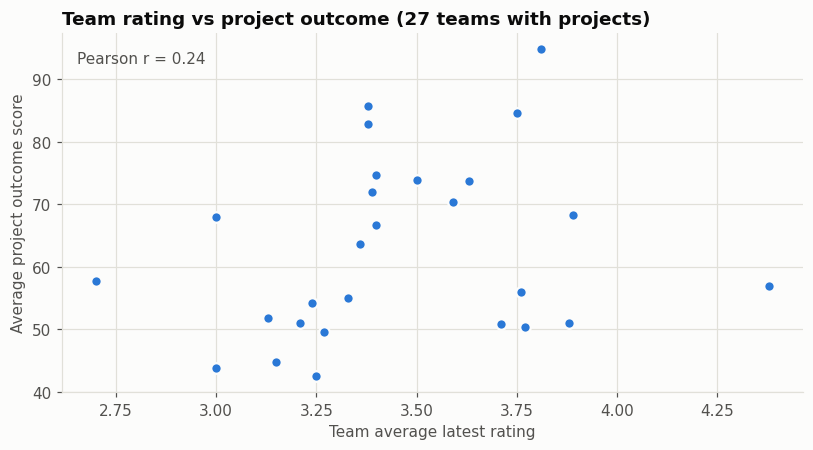

,avg_latest_rating,pct_high_performers,avg_critical_gaps
mostly_on_time,,,
Teams with mostly delayed projects,3.17,43.23,0.20
Teams with ≥50% on-time projects,3.55,53.82,0.16


In [9]:
teams = read_gold("team_performance")
with_projects = teams[teams["has_projects"]].astype({"avg_latest_rating": float, "avg_project_outcome_score": float})
corr = with_projects["avg_latest_rating"].corr(with_projects["avg_project_outcome_score"])

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.scatter(with_projects["avg_latest_rating"], with_projects["avg_project_outcome_score"],
           s=48, color=BLUE, edgecolor=SURFACE, linewidth=1.5)
ax.set_xlabel("Team average latest rating")
ax.set_ylabel("Average project outcome score")
ax.set_title(f"Team rating vs project outcome ({len(with_projects)} teams with projects)")
ax.text(0.02, 0.95, f"Pearson r = {corr:.2f}", transform=ax.transAxes, color=MUTED, va="top")
plt.tight_layout()
plt.show()

by_status = with_projects.assign(mostly_on_time=with_projects["pct_projects_on_time"] >= 50).groupby("mostly_on_time")[
    ["avg_latest_rating", "pct_high_performers", "avg_critical_gaps"]].mean().round(2)
by_status.index = by_status.index.map({True: "Teams with ≥50% on-time projects", False: "Teams with mostly delayed projects"})
by_status

**Answer:** across the teams that have projects, higher team ratings go with somewhat better project outcomes, but the
relationship is **weak** (see *r* above) and based on few teams. Treat it as a signal to investigate, not as proof
that ratings drive project success. Linking projects to individual employees would allow a stronger analysis.

## 7. What is the distribution of skills across the organization?

**Gold table:** `skill_distribution` — one row per department per competency (proficiency levels 1–5).

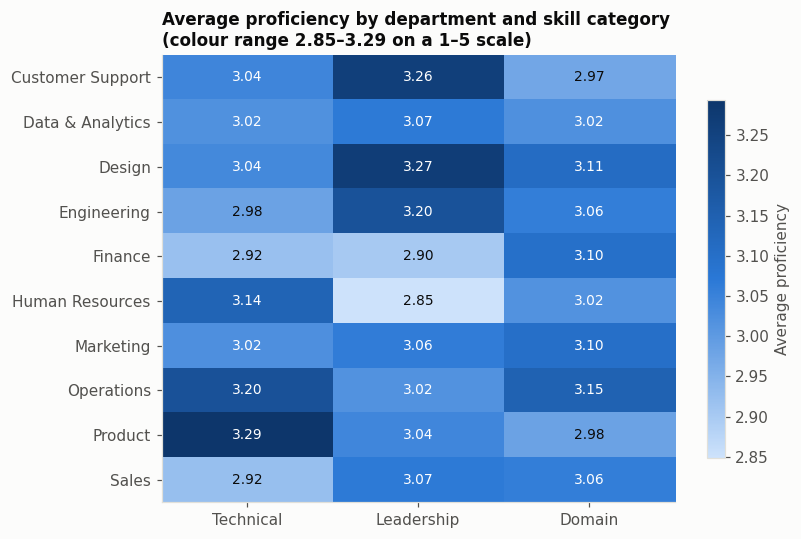

,level_1,level_2,level_3,level_4,level_5
% of assessments,12.6,20.6,27.9,26.2,12.7


In [10]:
skills = read_gold("skill_distribution")
heat = skills.groupby(["department", "category"]).apply(
    lambda g: (g["avg_proficiency"] * g["employees_assessed"]).sum() / g["employees_assessed"].sum(),
    include_groups=False).unstack("category")[["Technical", "Leadership", "Domain"]].sort_index()

fig, ax = plt.subplots(figsize=(7.5, 5))
image = ax.imshow(heat.values, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    "blue", ["#cde2fb", "#2a78d6", "#0d366b"]), aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(heat.shape[0]), heat.index)
ax.grid(False)
low, high = heat.values.min(), heat.values.max()
for (i, j), value in pd.DataFrame(heat.values).stack().items():
    dark_cell = (value - low) / (high - low) >= 0.35          # white text only on darker blues
    ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9, color="white" if dark_cell else TEXT)
ax.set_title(f"Average proficiency by department and skill category\n(colour range {low:.2f}–{high:.2f} on a 1–5 scale)", fontsize=11)
fig.colorbar(image, ax=ax, shrink=0.8, label="Average proficiency")
plt.tight_layout()
plt.show()

levels = skills[[f"level_{n}" for n in range(1, 6)]].sum()
(levels / levels.sum() * 100).round(1).rename("% of assessments").to_frame().T

**Answer:** proficiency is **fairly even** across the organization — every department/category average sits close to 3
on the 1–5 scale, so the colour range is deliberately narrow to make the differences visible. Relative strengths stand out
(for example Product in Technical skills, Design and Customer Support in Leadership) as do relative weaknesses (for example
Human Resources in Leadership). The table shows the overall spread of proficiency levels. Use it with Section 2 to plan
training by department.

## Summary, assumptions and limitations

| # | Question | Gold dataset | Confidence |
|---|---|---|---|
| 1 | Ratings & review history | `employee_performance_history` | High — complete for all employees, two periods |
| 2 | Critical skill gaps | `employee_skill_gaps`, `competency_coverage` | High — rule: gap ≥ 2 levels |
| 3 | High-potential, promotion-ready | `promotion_readiness` | High — rule combines talent review, rating, gaps |
| 4 | Training completed | `employee_training_summary`, `employee_course_progress` | High — quarantined events excluded |
| 5 | Attrition risk | `attrition_risk` | **Medium** — rule-based score; no leaver data; only two reviews |
| 6 | Performance vs teams & projects | `team_performance` | **Low** — team-level only, few teams with projects |
| 7 | Skill distribution | `skill_distribution` | High |

* Thresholds (critical gap ≥ 2, low rating ≤ 2, high rating ≥ 4, 12-month activity window) are named constants in
  `data/acme-performance/job.py` and can be changed in one place.
* Learning-event times have no time zone in the source; they are stored as UTC.
* "Last 12 months" is measured from the latest event in the data (the as-of date), not today's date.